<a href="https://colab.research.google.com/github/putriekasfr/UAS-DL-Kelompok5-T1A-TXL-PBC/blob/main/01_M2_Audit_EDA_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone M2 · Audit Data, EDA, Pemeriksaan Kebocoran, dan Baseline (Topik T1-A)
*Lanjutan: `02_M3_Main_Experiments_Ablations_XAI.ipynb`*
**Deep Learning A · Tugas Besar Pengganti UAS**
Tsabita Shafa Aurellia (`240441100052`) · Putri Eka Safira (`240441100087`)

**Pertanyaan riset (Daftar Topik T1-A):** seberapa kuat korelasi antara mAP@[0.5:0.95] dan galat hitung sel per citra
(MAE/MAPE per kelas) pada detektor one-stage (YOLOv8s) dan two-stage (Faster R-CNN ResNet-50-FPN)?
Dataset TXL-PBC (Gan, Li & Wang, 2025), split resmi, seed 42. M2 menyiapkan data dan dua baseline; korelasi antar run
dihitung di M3 setelah ablasi dan 3 seed selesai.

| Bagian | Isi | Pemilik | GPU |
|---|---|---|---|
| A | Audit data & EDA | Tsabita | tidak |
| B | Split, konversi YOLO → COCO + verifikasi 20 citra, pemeriksaan kebocoran | Putri | tidak |
| C | Baseline R01 YOLOv8s (one-stage) | Tsabita | T4 |
| D | Baseline R02 Faster R-CNN (two-stage) | Putri | T4 |
| E | Evaluasi terpadu pycocotools + galat hitung | Tsabita | tidak |
| F | Penutup: log eksperimen & berkas hasil (singkat) | Bersama | tidak |

**Cara menjalankan:** folder proyek ada di `MyDrive/UAS-DL-T1A-TXL-PBC` (dibagikan ke kedua anggota). Bagian A–B bisa
dijalankan dengan CPU. Untuk Bagian C–D pilih **Runtime → Change runtime type → T4 GPU**, lalu atur saklar
`PELAKSANA` di awal Bagian C: Tsabita menjalankan R01, Putri menjalankan R02 dari akunnya
masing-masing. Hasil keduanya tersimpan di folder Drive yang sama. Bagian dikerjakan selang-seling
(Tsabita → Putri → Tsabita → Putri → Tsabita); hanya penutup F yang bersama.

In [ ]:
# === Setup: jalankan sel ini pertama kali ===
import os, sys, subprocess

PIP_PAKET = ['openpyxl', 'ultralytics', 'pycocotools']   # hanya paket yang belum ada di Colab; torch/torchvision TIDAK dipasang ulang

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Cari folder proyek di Drive secara otomatis (folder yang berisi src/pipeline.py dan notebooks/),
    # termasuk folder yang dibagikan lewat shortcut. Nama folder tidak harus persis sama.
    import glob
    kandidat = [os.path.dirname(os.path.dirname(p)) for pola in
                ["/content/drive/MyDrive/src/pipeline.py",
                 "/content/drive/MyDrive/*/src/pipeline.py",
                 "/content/drive/MyDrive/*/*/src/pipeline.py",
                 "/content/drive/MyDrive/*/*/*/src/pipeline.py"]
                for p in glob.glob(pola)]
    kandidat = [k for k in kandidat if os.path.isdir(os.path.join(k, "notebooks"))]
    assert kandidat, "Folder proyek tidak ditemukan di Google Drive. Unggah folder hasil ekstrak zip ke My Drive."
    VERSI = "HEMAT-2026-11-23"   # hanya folder dengan berkas VERSION persis ini yang dipakai (folder lama diabaikan)
    def _versi(k):
        f = os.path.join(k, "VERSION")
        return open(f).read().strip() if os.path.exists(f) else "-"
    semua = sorted(set(os.path.realpath(k) for k in kandidat))
    kandidat = [k for k in semua if _versi(k) == VERSI]
    print("Folder proyek di Drive:")
    for k in semua:
        print(f"  {'→ DIPAKAI ' if kandidat and k == kandidat[0] else '  diabaikan'} {k}  (VERSION: {_versi(k)})")
    assert kandidat, (f"Folder versi {VERSI} tidak ditemukan. Ekstrak zip UAS-DL-T1A-TXL-PBC_HEMAT lalu unggah foldernya ke My Drive "
                      "(akun Putri: Add shortcut ke folder milik Tsabita).")
    assert len(kandidat) == 1, "Ada lebih dari satu folder versi ini di Drive; sisakan satu (hapus/ganti nama yang lain)."
    PROJECT = kandidat[0]
    os.chdir(PROJECT)
    if not os.path.isdir("/content/TXL-PBC_Dataset/TXL-PBC"):  # dataset diunduh ke disk lokal Colab (lebih cepat)
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/lugan113/TXL-PBC_Dataset", "/content/TXL-PBC_Dataset"], check=True)
    if PIP_PAKET:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PIP_PAKET],
                           capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-2000:], r.stderr[-3000:])
            raise RuntimeError("pip install gagal; salin pesan di atas untuk diperiksa")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from src.paths import *
DATA_ROOT = find_data_root()
print("Proyek :", os.getcwd())
print("Dataset:", DATA_ROOT)
print("Python :", sys.version.split()[0])

Mounted at /content/drive
Folder proyek di Drive:
  → DIPAKAI  /content/drive/MyDrive/Colab Notebooks/UAS  (VERSION: HEMAT-2026-11-23)
Proyek : /content/drive/MyDrive/Colab Notebooks/UAS
Dataset: /content/TXL-PBC_Dataset/TXL-PBC
Python : 3.13.16


## Bagian A · Audit Data dan EDA — Tsabita
Jumlah citra, distribusi kelas, objek per citra, sebaran ukuran, tumpang tindih, ukuran per sumber, dan contoh visual
per kelas (kisi-kisi 3.1). Semua angka dihitung langsung dari label YOLO resmi; tabel dan gambar disimpan ke `outputs/eda/`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageDraw
from src.data_utils import load_boxes, count_duplicate_lines
from src.viz import style, label_bars, BAR, CLASS_COLORS, SOURCE_COLORS, SPLIT_COLORS, INK_2

style()
EDA_DIR = OUTPUT_DIR / "eda"
FIG_DIR = OUTPUT_DIR / "figures"
EDA_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 2000)

df_img_raw, df_box_raw = load_boxes(DATA_ROOT, dedup=False)   # label persis seperti rilis
df_img, df_box = load_boxes(DATA_ROOT, dedup=True)             # setelah baris duplikat dibuang
SOURCES = sorted(df_img.source.unique())
print(f"{len(df_img)} citra · {len(df_box_raw)} kotak di berkas rilis · {len(df_box)} kotak unik")

1260 citra · 18143 kotak di berkas rilis · 18096 kotak unik


### A.0 Kualitas label: baris duplikat
Beberapa berkas label memuat baris yang identik persis (kelas dan koordinat sama), sehingga satu sel terhitung dua kali.
Untuk tugas penghitungan sel ini berpengaruh langsung pada ground truth jumlah sel. Ultralytics membuang duplikat ini
secara otomatis saat memuat label, jadi kami membuangnya juga di semua analisis dan di anotasi COCO agar YOLOv8 dan
Faster R-CNN dinilai terhadap label yang sama. Seluruh angka setelah bagian ini memakai label unik.

In [ ]:
dup = count_duplicate_lines(DATA_ROOT)
dup.to_csv(EDA_DIR / "label_duplikat.csv", index=False)
print(f"{dup.duplikat.sum()} baris duplikat di {len(dup)} berkas label")
display(dup)

47 baris duplikat di 5 berkas label


,split,stem,baris_asli,baris_unik,duplikat,dup_WBC,dup_RBC,dup_Platelets
0,train,92129d1652e75c3892beb376df57d274,13,12,1,0,1,0
1,train,a8581e04ac765bd3ad658cf8e530a6ea,18,17,1,0,1,0
2,train,c255521a08b75da09373db44e7f099c5,32,15,17,5,12,0
3,val,0ac132c270355979b686c0801e558849,31,16,15,0,15,0
4,test,1299047edeb15e2581d9680aaa667d5d,26,13,13,2,11,0


### A.1 Tabel audit: citra per sumber dan split, distribusi kelas, objek per citra

In [ ]:
print("=== 1a. Jumlah citra per sumber dan split ===")
tab_src = pd.crosstab(df_img.source, df_img.split, margins=True, margins_name="Total")[["train", "val", "test", "Total"]]
tab_src.to_csv(EDA_DIR / "citra_per_sumber_split.csv")
display(tab_src)

print("\n=== 1b. Jumlah kotak per kelas dan split ===")
tab_cls = pd.crosstab(df_box.cls, df_box.split, margins=True, margins_name="Total")
tab_cls = tab_cls.loc[CLASSES + ["Total"], ["train", "val", "test", "Total"]]
tab_cls["% dari total kotak"] = (tab_cls["Total"] / len(df_box) * 100).round(1)
tab_cls.to_csv(EDA_DIR / "distribusi_kelas.csv")
display(tab_cls)

print("\n=== 1c. Proporsi kelas per split (%) ===")
prop = pd.crosstab(df_box.split, df_box.cls, normalize="index").loc[["train", "val", "test"], CLASSES] * 100
display(prop.round(2))

print("\n=== 1d. Objek per citra ===")
desc = df_img[CLASSES + ["n_boxes"]].describe().T[["mean", "std", "min", "50%", "max"]]
desc.to_csv(EDA_DIR / "objek_per_citra.csv")
display(desc)

print("\n=== 1e. Kondisi citra yang dipakai analisis galat hitung (H2) ===")
summary = pd.DataFrame({
    "citra": df_img.groupby("split").size(),
    "RBC > 15 (padat)": df_img[df_img.RBC > 15].groupby("split").size(),
    "tanpa platelet": df_img[df_img.Platelets == 0].groupby("split").size(),
    "tanpa WBC": df_img[df_img.WBC == 0].groupby("split").size(),
    "WBC > 1": df_img[df_img.WBC > 1].groupby("split").size(),
}).reindex(["train", "val", "test"]).fillna(0).astype(int)
summary.to_csv(EDA_DIR / "kondisi_citra.csv")
display(summary)

=== 1a. Jumlah citra per sumber dan split ===


split,train,val,test,Total
source,,,,
BCCD,101,41,18,160
BCDD,70,16,14,100
PBC,353,97,50,500
Raabin-WBC,358,98,44,500
Total,882,252,126,1260



=== 1b. Jumlah kotak per kelas dan split ===


split,train,val,test,Total,% dari total kotak
cls,,,,,
WBC,903,257,131,1291,7.1
RBC,11206,3368,1688,16262,89.9
Platelets,382,112,49,543,3.0
Total,12491,3737,1868,18096,100.0



=== 1c. Proporsi kelas per split (%) ===


cls,WBC,RBC,Platelets
split,,,
train,7.23,89.71,3.06
val,6.88,90.13,3.00
test,7.01,90.36,2.62



=== 1d. Objek per citra ===


,mean,std,min,50%,max
WBC,1.02,0.18,0.0,1.0,2.0
RBC,12.91,4.38,3.0,12.0,29.0
Platelets,0.43,0.86,0.0,0.0,6.0
n_boxes,14.36,4.62,4.0,14.0,30.0



=== 1e. Kondisi citra yang dipakai analisis galat hitung (H2) ===


,citra,RBC > 15 (padat),tanpa platelet,tanpa WBC,WBC > 1
split,,,,,
train,882,204,637,3,24
val,252,69,188,2,7
test,126,34,92,0,5


### A.2 Tabel audit: ukuran objek, tumpang tindih, ukuran per sumber
Kategori ukuran mengikuti COCO: *small* < 32² px, *medium* 32²–96² px, *large* > 96² px (luas kotak dalam piksel
citra asli). NMS menghapus kotak yang IoU-nya dengan kotak lain di atas ambang (Faster R-CNN 0,5; YOLOv8 0,7); bila
dua sel asli saling tumpang tindih di atas ambang itu, salah satunya bisa ikut terhapus dan hitungan berkurang.

In [ ]:
df_box["side"] = df_box.area ** 0.5
df_box["size_cat"] = np.where(df_box.area < 32**2, "small", np.where(df_box.area < 96**2, "medium", "large"))
print("=== 2a. Kategori ukuran COCO per kelas ===")
tab_size = pd.crosstab(df_box.cls, df_box.size_cat).reindex(index=CLASSES, columns=["small", "medium", "large"], fill_value=0)
tab_size["% small"] = (tab_size["small"] / tab_size.sum(axis=1) * 100).round(1)
tab_size["sisi median (px)"] = df_box.groupby("cls").side.median().reindex(CLASSES).round(1)
tab_size.to_csv(EDA_DIR / "kategori_ukuran.csv")
display(tab_size)

def iou_matrix(b):
    x0, y0, x1, y1 = b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(x1[:, None], x1) - np.maximum(x0[:, None], x0), 0, None)
    ih = np.clip(np.minimum(y1[:, None], y1) - np.maximum(y0[:, None], y0), 0, None)
    inter = iw * ih
    area = b[:, 2] * b[:, 3]
    return inter / (area[:, None] + area - inter)

rows = []
for (split, stem, cls), g in df_box.groupby(["split", "stem", "cls"]):
    if len(g) < 2:
        rows.append(dict(cls=cls, max_iou=0.0)); continue
    M = iou_matrix(g[["x", "y", "w", "h"]].values)
    np.fill_diagonal(M, 0)
    rows += [dict(cls=cls, max_iou=v) for v in M.max(1)]
ov = pd.DataFrame(rows)
tab_ov = ov.groupby("cls").max_iou.agg(
    kotak="size",
    **{"IoU>0.3 (%)": lambda s: (s > 0.3).mean() * 100,
       "IoU>0.5 (%)": lambda s: (s > 0.5).mean() * 100,
       "IoU>0.7 (%)": lambda s: (s > 0.7).mean() * 100}).reindex(CLASSES)
tab_ov.to_csv(EDA_DIR / "tumpang_tindih.csv")
print("\n=== 2b. Persentase kotak yang punya tetangga sekelas dengan IoU di atas ambang ===")
display(tab_ov.round(2))

print("\n=== 2c. Resolusi citra per sumber ===")
df_img["resolusi"] = df_img.width.astype(str) + "×" + df_img.height.astype(str)
display(pd.crosstab(df_img.source, df_img.resolusi))

print("\n=== 2d. Sisi kotak median (px) per sumber dan rata-rata objek per citra per sumber ===")
side = df_box.pivot_table(index="source", columns="cls", values="side", aggfunc="median")[CLASSES]
per_img_src = df_img.groupby("source")[CLASSES].mean()
tab_srcsize = pd.concat({"sisi median (px)": side, "objek per citra": per_img_src}, axis=1)
tab_srcsize.to_csv(EDA_DIR / "ukuran_dan_jumlah_per_sumber.csv")
display(tab_srcsize.round(2))

=== 2a. Kategori ukuran COCO per kelas ===


size_cat,small,medium,large,% small,sisi median (px)
cls,,,,,
WBC,0,78,1213,0.0,185.0
RBC,0,9399,6863,0.0,87.0
Platelets,237,305,1,43.6,33.5



=== 2b. Persentase kotak yang punya tetangga sekelas dengan IoU di atas ambang ===


,kotak,IoU>0.3 (%),IoU>0.5 (%),IoU>0.7 (%)
cls,,,,
WBC,1291,0.15,0.15,0.00
RBC,16262,3.42,0.29,0.01
Platelets,543,0.00,0.00,0.00



=== 2c. Resolusi citra per sumber ===


resolusi,256×256,360×363,366×369,575×575,640×480
source,,,,,
BCCD,0,0,0,0,160
BCDD,100,0,0,0,0
PBC,0,486,14,0,0
Raabin-WBC,0,0,0,500,0



=== 2d. Sisi kotak median (px) per sumber dan rata-rata objek per citra per sumber ===


sisi median (px)                   objek per citra                 
cls                     WBC     RBC Platelets             WBC    RBC Platelets
source                                                                        
BCCD                 207.40   99.00     39.47            1.02  19.87      1.04
BCDD                  93.49   58.89     18.44            1.00  16.34      0.03
PBC                  137.06   74.51     30.94            1.04  12.57      0.68
Raabin-WBC           262.79  128.86     53.68            1.02  10.32      0.06

### A.3 Grafik EDA

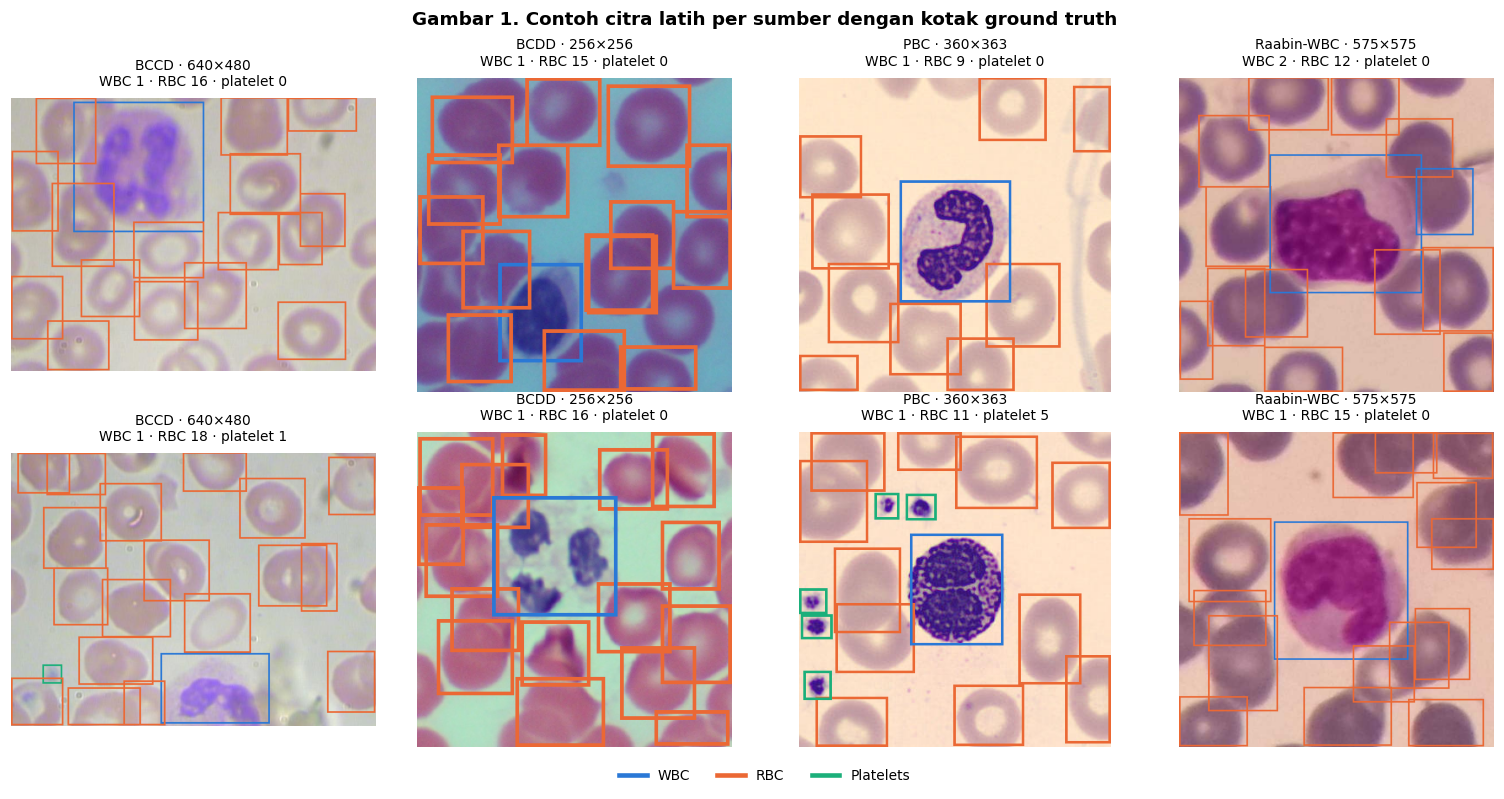

In [ ]:
# Gambar 1 · contoh citra latih per sumber dengan kotak ground truth
rng = np.random.RandomState(SEED)
def draw(stem, split, width=3):
    im = Image.open(DATA_ROOT / "images" / split / f"{stem}.png").convert("RGB")
    d = ImageDraw.Draw(im)
    for r in df_box[df_box.stem == stem].itertuples():
        d.rectangle([r.x, r.y, r.x + r.w, r.y + r.h], outline=CLASS_COLORS[r.cls], width=width)
    return im

fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))
for j, s in enumerate(SOURCES):
    pick = df_img[(df_img.source == s) & (df_img.split == "train")].sample(2, random_state=rng)
    for i, r in enumerate(pick.itertuples()):
        ax = axes[i, j]
        ax.imshow(draw(r.stem, r.split)); ax.axis("off")
        ax.set_title(f"{s} · {r.width}×{r.height}\nWBC {r.WBC} · RBC {r.RBC} · platelet {r.Platelets}", fontsize=9, fontweight="normal")
handles = [plt.Line2D([], [], color=c, lw=3, label=k) for k, c in CLASS_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Gambar 1. Contoh citra latih per sumber dengan kotak ground truth", fontweight="semibold")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "fig1_contoh_per_sumber.png")
plt.show()

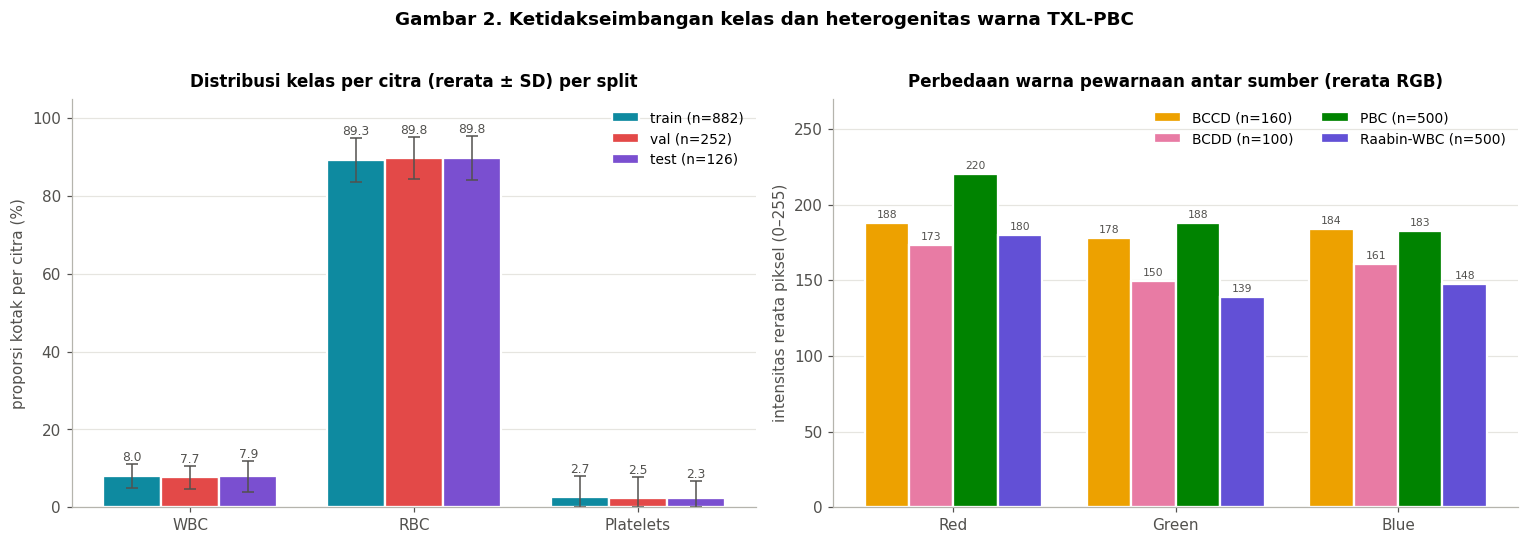

In [ ]:
# Gambar 2 · distribusi kelas per split dan perbedaan warna antar sumber
rgb = []
for r in df_img.itertuples():
    a = np.asarray(Image.open(DATA_ROOT / "images" / r.split / f"{r.stem}.png").convert("RGB"), dtype=np.float32)
    rgb.append(a.reshape(-1, 3).mean(0))
df_img[["R", "G", "B"]] = np.array(rgb)

frac = df_img[CLASSES].div(df_img[CLASSES].sum(1), axis=0) * 100        # proporsi kelas per citra
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
w = 0.26
for k, s in enumerate(["train", "val", "test"]):
    sub = frac[df_img.split == s]
    m, sd = sub.mean(), sub.std()
    x = np.arange(3) + (k - 1) * w
    err = np.vstack([np.minimum(sd.values, m.values), sd.values])   # SD dipotong di 0: proporsi tidak bisa negatif
    bars = ax.bar(x, m.values, w, yerr=err, capsize=4, color=SPLIT_COLORS[s],
                  error_kw=dict(ecolor=INK_2, lw=1), label=f"{s} (n={len(sub)})", **BAR)
    for b, mm, ss in zip(bars, m.values, sd.values):
        ax.annotate(f"{mm:.1f}", (b.get_x() + b.get_width() / 2, mm + ss), xytext=(0, 2),
                    textcoords="offset points", ha="center", fontsize=8, color=INK_2)
ax.set_xticks(range(3), CLASSES); ax.set_ylabel("proporsi kotak per citra (%)"); ax.set_ylim(0, 105)
ax.set_title("Distribusi kelas per citra (rerata ± SD) per split"); ax.legend(loc="upper right")

ax = axes[1]
w = 0.2
for k, s in enumerate(SOURCES):
    m = df_img[df_img.source == s][["R", "G", "B"]].mean()
    x = np.arange(3) + (k - 1.5) * w
    bars = ax.bar(x, m.values, w, color=SOURCE_COLORS[s], label=f"{s} (n={(df_img.source == s).sum()})", **BAR)
    label_bars(ax, bars, "{:.0f}", fontsize=7)
ax.set_xticks(range(3), ["Red", "Green", "Blue"]); ax.set_ylabel("intensitas rerata piksel (0–255)")
ax.set_ylim(0, 270); ax.set_title("Perbedaan warna pewarnaan antar sumber (rerata RGB)")
ax.legend(loc="upper right", ncol=2)
fig.suptitle("Gambar 2. Ketidakseimbangan kelas dan heterogenitas warna TXL-PBC", fontweight="semibold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_eda_distribusi.png")
plt.show()
df_img.groupby("source")[["R", "G", "B"]].mean().round(1).to_csv(EDA_DIR / "rgb_per_sumber.csv")

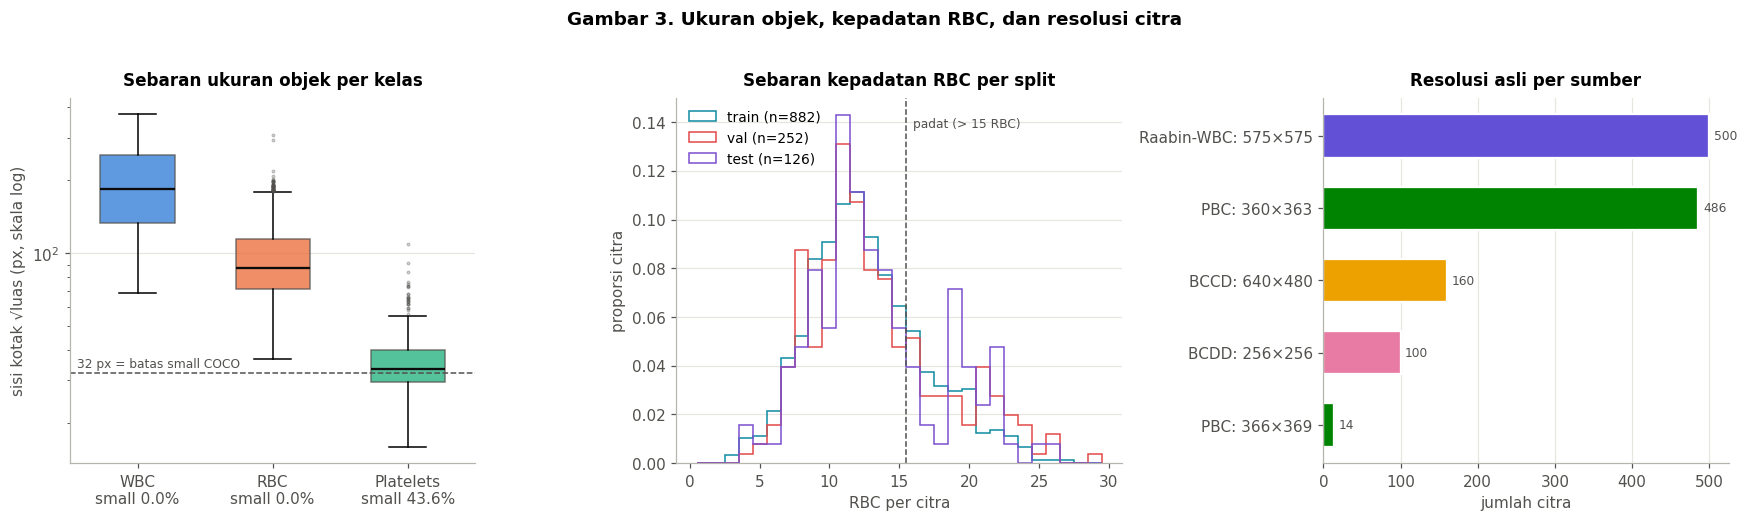

In [ ]:
# Gambar 3 · ukuran objek, kepadatan RBC, dan resolusi citra
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1.1, 1]))
ax = axes[0]
data = [df_box[df_box.cls == c].side.values for c in CLASSES]
ticks = [f"{c}\nsmall {(df_box[df_box.cls == c].area < 32**2).mean() * 100:.1f}%" for c in CLASSES]
bp = ax.boxplot(data, tick_labels=ticks, patch_artist=True, widths=0.55,
                medianprops=dict(color="#0b0b0b", lw=1.5), flierprops=dict(marker=".", ms=3, alpha=0.4, mec=INK_2))
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(CLASS_COLORS[c]); patch.set_alpha(0.75); patch.set_edgecolor(INK_2)
ax.set_yscale("log"); ax.axhline(32, color=INK_2, ls="--", lw=1)
ax.text(0.55, 33, "32 px = batas small COCO", fontsize=8, color=INK_2, ha="left", va="bottom")
ax.set_ylabel("sisi kotak √luas (px, skala log)"); ax.set_title("Sebaran ukuran objek per kelas")

ax = axes[1]
bins = np.arange(0.5, df_img.RBC.max() + 1.5, 1)
for s in ["train", "val", "test"]:
    sub = df_img[df_img.split == s].RBC
    ax.hist(sub, bins=bins, density=True, histtype="step", lw=2, color=SPLIT_COLORS[s], label=f"{s} (n={len(sub)})")
ax.axvline(15.5, color=INK_2, ls="--", lw=1); ax.text(16, ax.get_ylim()[1] * 0.92, "padat (> 15 RBC)", fontsize=8, color=INK_2)
ax.set_xlabel("RBC per citra"); ax.set_ylabel("proporsi citra"); ax.set_title("Sebaran kepadatan RBC per split")
ax.legend(loc="upper left")

ax = axes[2]
res = df_img.groupby(["source", "resolusi"]).size().reset_index(name="n").sort_values("n")
ylab = [f"{r.source}: {r.resolusi}" for r in res.itertuples()]
bars = ax.barh(ylab, res.n, color=[SOURCE_COLORS[s] for s in res.source], height=0.6, **BAR)
for b in bars:
    ax.annotate(f"{int(b.get_width())}", (b.get_width(), b.get_y() + b.get_height() / 2), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK_2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("jumlah citra"); ax.set_title("Resolusi asli per sumber")
fig.suptitle("Gambar 3. Ukuran objek, kepadatan RBC, dan resolusi citra", fontweight="semibold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_ukuran_kepadatan_resolusi.png")
plt.show()

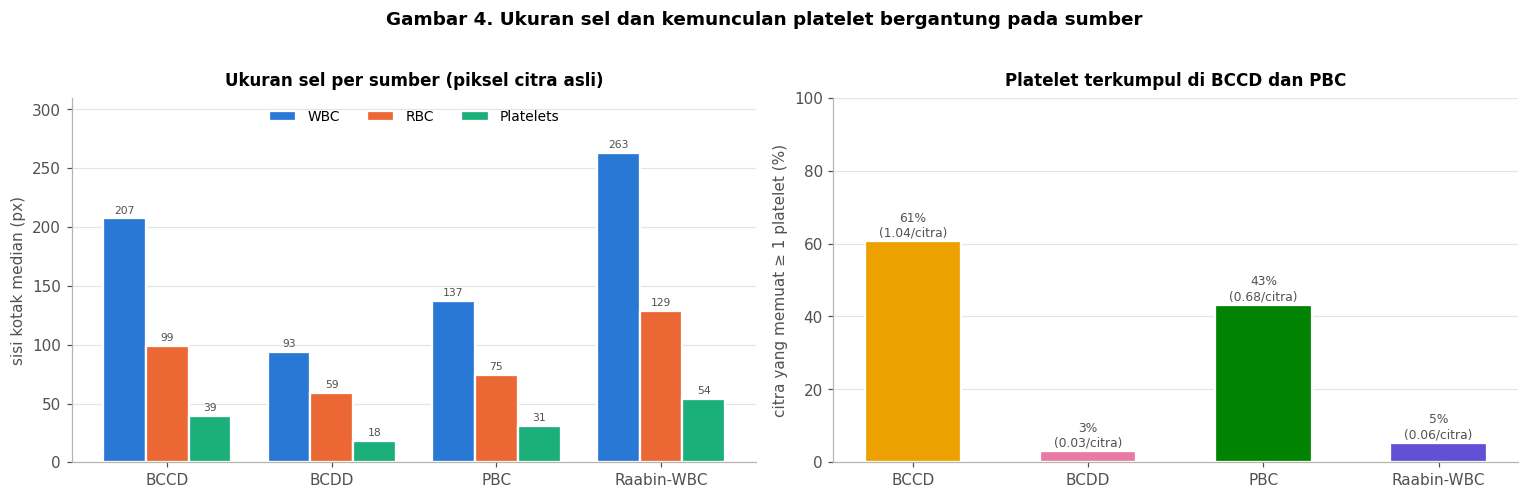

In [ ]:
# Gambar 4 · ukuran sel dan jumlah platelet bergantung pada sumber
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
w = 0.26
for k, c in enumerate(CLASSES):
    x = np.arange(len(SOURCES)) + (k - 1) * w
    bars = ax.bar(x, side.loc[SOURCES, c].values, w, color=CLASS_COLORS[c], label=c, **BAR)
    label_bars(ax, bars, "{:.0f}", fontsize=7)
ax.set_xticks(range(len(SOURCES)), SOURCES); ax.set_ylabel("sisi kotak median (px)")
ax.set_ylim(0, 310); ax.set_title("Ukuran sel per sumber (piksel citra asli)"); ax.legend(loc="upper center", ncol=3)

ax = axes[1]
has = (df_img.Platelets > 0).groupby(df_img.source).mean().reindex(SOURCES) * 100
mean_plt = df_img.groupby("source").Platelets.mean().reindex(SOURCES)
bars = ax.bar(SOURCES, has.values, 0.55, color=[SOURCE_COLORS[s] for s in SOURCES], **BAR)
for b_, pct, mm in zip(bars, has.values, mean_plt.values):
    ax.annotate(f"{pct:.0f}%\n({mm:.2f}/citra)", (b_.get_x() + b_.get_width() / 2, pct), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8, color=INK_2)
ax.set_ylim(0, 100); ax.set_ylabel("citra yang memuat ≥ 1 platelet (%)")
ax.set_title("Platelet terkumpul di BCCD dan PBC")
fig.suptitle("Gambar 4. Ukuran sel dan kemunculan platelet bergantung pada sumber", fontweight="semibold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_ukuran_dan_platelet_per_sumber.png")
plt.show()

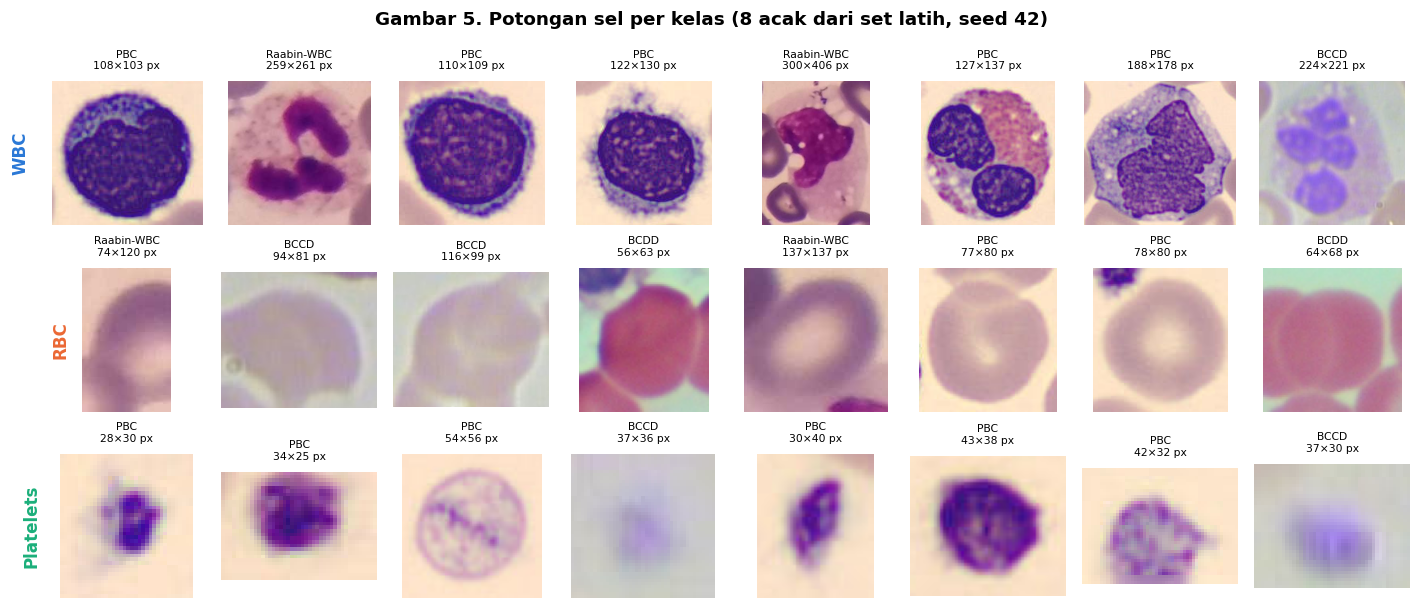

In [ ]:
# Gambar 5 · potongan sel per kelas
fig, axes = plt.subplots(3, 8, figsize=(13, 5.6))
for i, c in enumerate(CLASSES):
    pick = df_box[(df_box.cls == c) & (df_box.split == "train")].sample(8, random_state=SEED)
    for j, r in enumerate(pick.itertuples()):
        im = Image.open(DATA_ROOT / "images" / r.split / f"{r.stem}.png").convert("RGB")
        pad = 4
        crop = im.crop((max(0, r.x - pad), max(0, r.y - pad), min(im.width, r.x + r.w + pad), min(im.height, r.y + r.h + pad)))
        axes[i, j].imshow(crop); axes[i, j].axis("off")
        axes[i, j].set_title(f"{r.source}\n{int(r.w)}×{int(r.h)} px", fontsize=7, fontweight="normal")
    axes[i, 0].text(-0.15, 0.5, c, transform=axes[i, 0].transAxes, rotation=90, va="center", ha="right",
                    fontsize=11, color=CLASS_COLORS[c], fontweight="semibold")
fig.suptitle("Gambar 5. Potongan sel per kelas (8 acak dari set latih, seed 42)", fontweight="semibold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_potongan_per_kelas.png")
plt.show()

### A.4 Temuan dan dampaknya pada desain eksperimen

| No | Temuan (angka dari sel di atas) | Dampak pada desain |
|---|---|---|
| 1 | **Label duplikat:** 47 baris identik di 5 berkas (3 latih, 1 validasi, 1 uji). Setelah dibuang: 18.096 kotak unik dari 18.143 di rilis. Satu citra uji tercatat 26 kotak padahal hanya 13 sel. | Ground truth COCO memakai label unik (sama dengan perilaku ultralytics). Tanpa ini, MAE hitung citra tersebut naik palsu ±13 sel. Dilaporkan di Bab Data. |
| 2 | **Kelas sangat timpang:** RBC 89,9%, WBC 7,1%, platelet 3,0%. Proporsi tiap split hampir sama (platelet 3,05 / 3,00 / 2,62%). | Split resmi representatif dan dipakai apa adanya. mAP harus dibaca per kelas, bukan rerata saja. |
| 3 | **Platelet jarang dan kecil:** 72% citra latih tanpa platelet; set uji hanya 49 platelet di 34 citra. 43,6% platelet < 32² px, sedangkan tidak ada WBC/RBC yang small. | AP_small pada dataset ini praktis = AP platelet kecil. MAPE platelet dihitung hanya pada citra yang memiliki platelet dan didampingi MAE. Variasi antar-seed platelet diperkirakan besar, sehingga 3 seed wajib. |
| 4 | **Ukuran sel bergantung sumber:** sisi median RBC 59 px (BCDD, 256²) hingga 129 px (Raabin, 575²); platelet 18 px di BCDD. Platelet terkumpul di BCCD (1,04/citra) dan PBC (0,68/citra), hampir tidak ada di BCDD (0,03) dan Raabin (0,06). | Galat hitung dilaporkan juga per sumber. Ablasi resolusi (A1) dan anchor kecil (A2) relevan karena ukuran piksel platelet berbeda antar sumber. |
| 5 | **WBC hampir selalu 1 per citra** (rerata 1,02; maks 2). | MAE WBC pada dasarnya mengukur WBC terlewat atau deteksi ganda, bukan masalah kepadatan. |
| 6 | **Kepadatan RBC:** 204 / 69 / 34 citra (latih/val/uji) memiliki > 15 RBC. | Cukup untuk menguji H2 (galat pada citra padat vs tidak padat). |
| 7 | **Tumpang tindih kecil:** hanya 0,29% kotak RBC punya tetangga dengan IoU > 0,5 dan 0,01% dengan IoU > 0,7. | NMS diperkirakan hanya menghapus sedikit sel asli. Jika RBC padat tetap kurang terhitung, penyebabnya lebih mungkin sel terlewat (tepi citra, sel terpotong) daripada NMS. Ini dicek di analisis kesalahan M3. |
| 8 | **Visual:** sel yang terpotong di tepi citra tetap dianotasi; latar BCDD biru-hijau, sumber lain merah muda/abu. | Augmentasi warna dibatasi (hue ±0,01) agar tidak merusak informasi pewarnaan; kategori "sel terpotong di tepi" ditambahkan ke galeri kesalahan. |

## Bagian B · Split, Konversi COCO, dan Pemeriksaan Kebocoran — Putri
Daftar split resmi disimpan ke `splits/`, label diperiksa, dikonversi ke COCO (diverifikasi angka dan visual 20 citra),
lalu duplikat antar-split diperiksa dengan MD5 dan perceptual hash (kisi-kisi 3.1 dan peringatan kebocoran Bagian 2).

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from src.data_utils import (write_split_files, read_split_file, list_split, read_yolo,
                            load_source_map, yolo_to_coco, count_duplicate_lines)
from src.leakage import hash_split, cross_pairs
from IPython.display import display
from src.viz import style, BAR, CLASS_COLORS, SOURCE_COLORS, SPLIT_COLORS, INK_2

style()
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

LEAK_DIR = OUTPUT_DIR / "leakage"
LEAK_DIR.mkdir(parents=True, exist_ok=True)

### B.1 Split resmi → `splits/{train,val,test}.txt`

In [ ]:
sizes = write_split_files(DATA_ROOT)
print("Jumlah citra per split:", sizes)
assert sizes == {"train": 882, "val": 252, "test": 126}, "Tidak sama dengan split resmi TXL-PBC"

stems = {s: set(read_split_file(s)) for s in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"Nama berkas sama di {a} & {b}: {len(stems[a] & stems[b])}")
for s in SPLITS:
    missing = [x for x in stems[s] if not (DATA_ROOT / "labels" / s / f"{x}.txt").exists()]
    print(f"{s}: citra tanpa berkas label = {len(missing)}")
print("\nSeed yang dipakai semua run utama:", SEED)

Jumlah citra per split: {'train': 882, 'val': 252, 'test': 126}
Nama berkas sama di train & val: 0
Nama berkas sama di train & test: 0
Nama berkas sama di val & test: 0
train: citra tanpa berkas label = 0
val: citra tanpa berkas label = 0
test: citra tanpa berkas label = 0

Seed yang dipakai semua run utama: 42


### B.2 Keabsahan label YOLO

In [ ]:
issues = []
for s in SPLITS:
    for stem in read_split_file(s):
        for c, xc, yc, w, h in read_yolo(DATA_ROOT / "labels" / s / f"{stem}.txt", dedup=False):
            if c not in (0, 1, 2):
                issues.append((s, stem, "kelas di luar 0-2"))
            if not (0 <= xc <= 1 and 0 <= yc <= 1):
                issues.append((s, stem, "pusat di luar citra"))
            if w <= 0 or h <= 0:
                issues.append((s, stem, "lebar/tinggi <= 0"))
            if xc - w / 2 < -0.01 or xc + w / 2 > 1.01 or yc - h / 2 < -0.01 or yc + h / 2 > 1.01:
                issues.append((s, stem, "kotak keluar tepi > 1%"))
iss = pd.DataFrame(issues, columns=["split", "stem", "masalah"])
print("Jumlah masalah koordinat/kelas:", len(iss))
display(iss.masalah.value_counts() if len(iss) else "tidak ada")

dup = count_duplicate_lines(DATA_ROOT)
print(f"Baris label identik (duplikat): {dup.duplikat.sum()} di {len(dup)} berkas -> dibuang saat konversi")
dup

Jumlah masalah koordinat/kelas: 0


'tidak ada'

Baris label identik (duplikat): 47 di 5 berkas -> dibuang saat konversi


,split,stem,baris_asli,baris_unik,duplikat,dup_WBC,dup_RBC,dup_Platelets
0,train,92129d1652e75c3892beb376df57d274,13,12,1,0,1,0
1,train,a8581e04ac765bd3ad658cf8e530a6ea,18,17,1,0,1,0
2,train,c255521a08b75da09373db44e7f099c5,32,15,17,5,12,0
3,val,0ac132c270355979b686c0801e558849,31,16,15,0,15,0
4,test,1299047edeb15e2581d9680aaa667d5d,26,13,13,2,11,0


### B.3 Konversi YOLO → COCO
Aturan konversi: `image_id` = urutan di `splits/<split>.txt`; `bbox` = [x_min, y_min, lebar, tinggi] dalam piksel citra asli;
`area` = lebar × tinggi (dipakai pycocotools untuk AP_small); `category_id` = indeks YOLO + 1 (WBC 1, RBC 2, Platelets 3);
baris duplikat dibuang.

In [ ]:
coco = {s: yolo_to_coco(DATA_ROOT, s, COCO_DIR / f"{s}.json") for s in SPLITS}

check = []
for s in SPLITS:
    n_yolo = sum(len(read_yolo(DATA_ROOT / "labels" / s / f"{x}.txt")) for x in read_split_file(s))
    per_cls = pd.Series([a["category_id"] for a in coco[s]["annotations"]]).value_counts().sort_index()
    check.append(dict(split=s, citra=len(coco[s]["images"]), kotak_YOLO_unik=n_yolo,
                      kotak_COCO=len(coco[s]["annotations"]),
                      WBC=per_cls.get(1, 0), RBC=per_cls.get(2, 0), Platelets=per_cls.get(3, 0)))
check = pd.DataFrame(check).set_index("split")
assert (check.kotak_YOLO_unik == check.kotak_COCO).all()
check

,citra,kotak_YOLO_unik,kotak_COCO,WBC,RBC,Platelets
split,,,,,,
train,882,12491,12491,903,11206,382
val,252,3737,3737,257,3368,112
test,126,1868,1868,131,1688,49


In [ ]:
# Uji bolak-balik: COCO -> YOLO ternormalisasi harus sama dengan label asli (toleransi pembulatan 0,01 px)
max_err = 0.0
for s in SPLITS:
    by_img = {}
    for a in coco[s]["annotations"]:
        by_img.setdefault(a["image_id"], []).append(a)
    for im in coco[s]["images"]:
        W, H = im["width"], im["height"]
        orig = read_yolo(DATA_ROOT / "labels" / s / im["file_name"].replace(".png", ".txt"))
        back = []
        for a in by_img.get(im["id"], []):
            x, y, w, h = a["bbox"]
            back.append((a["category_id"] - 1, (x + w / 2) / W, (y + h / 2) / H, w / W, h / H))
        assert len(orig) == len(back)
        for o, b in zip(orig, back):
            assert o[0] == b[0]
            # kotak yang dipotong di tepi citra tidak dibandingkan koordinatnya
            if o[1] - o[3] / 2 >= 0 and o[1] + o[3] / 2 <= 1 and o[2] - o[4] / 2 >= 0 and o[2] + o[4] / 2 <= 1:
                max_err = max(max_err, max(abs(o[k] * (W if k in (1, 3) else H) - b[k] * (W if k in (1, 3) else H)) for k in range(1, 5)))
print(f"Selisih maksimum koordinat setelah bolak-balik: {max_err:.3f} px")

Selisih maksimum koordinat setelah bolak-balik: 0.007 px


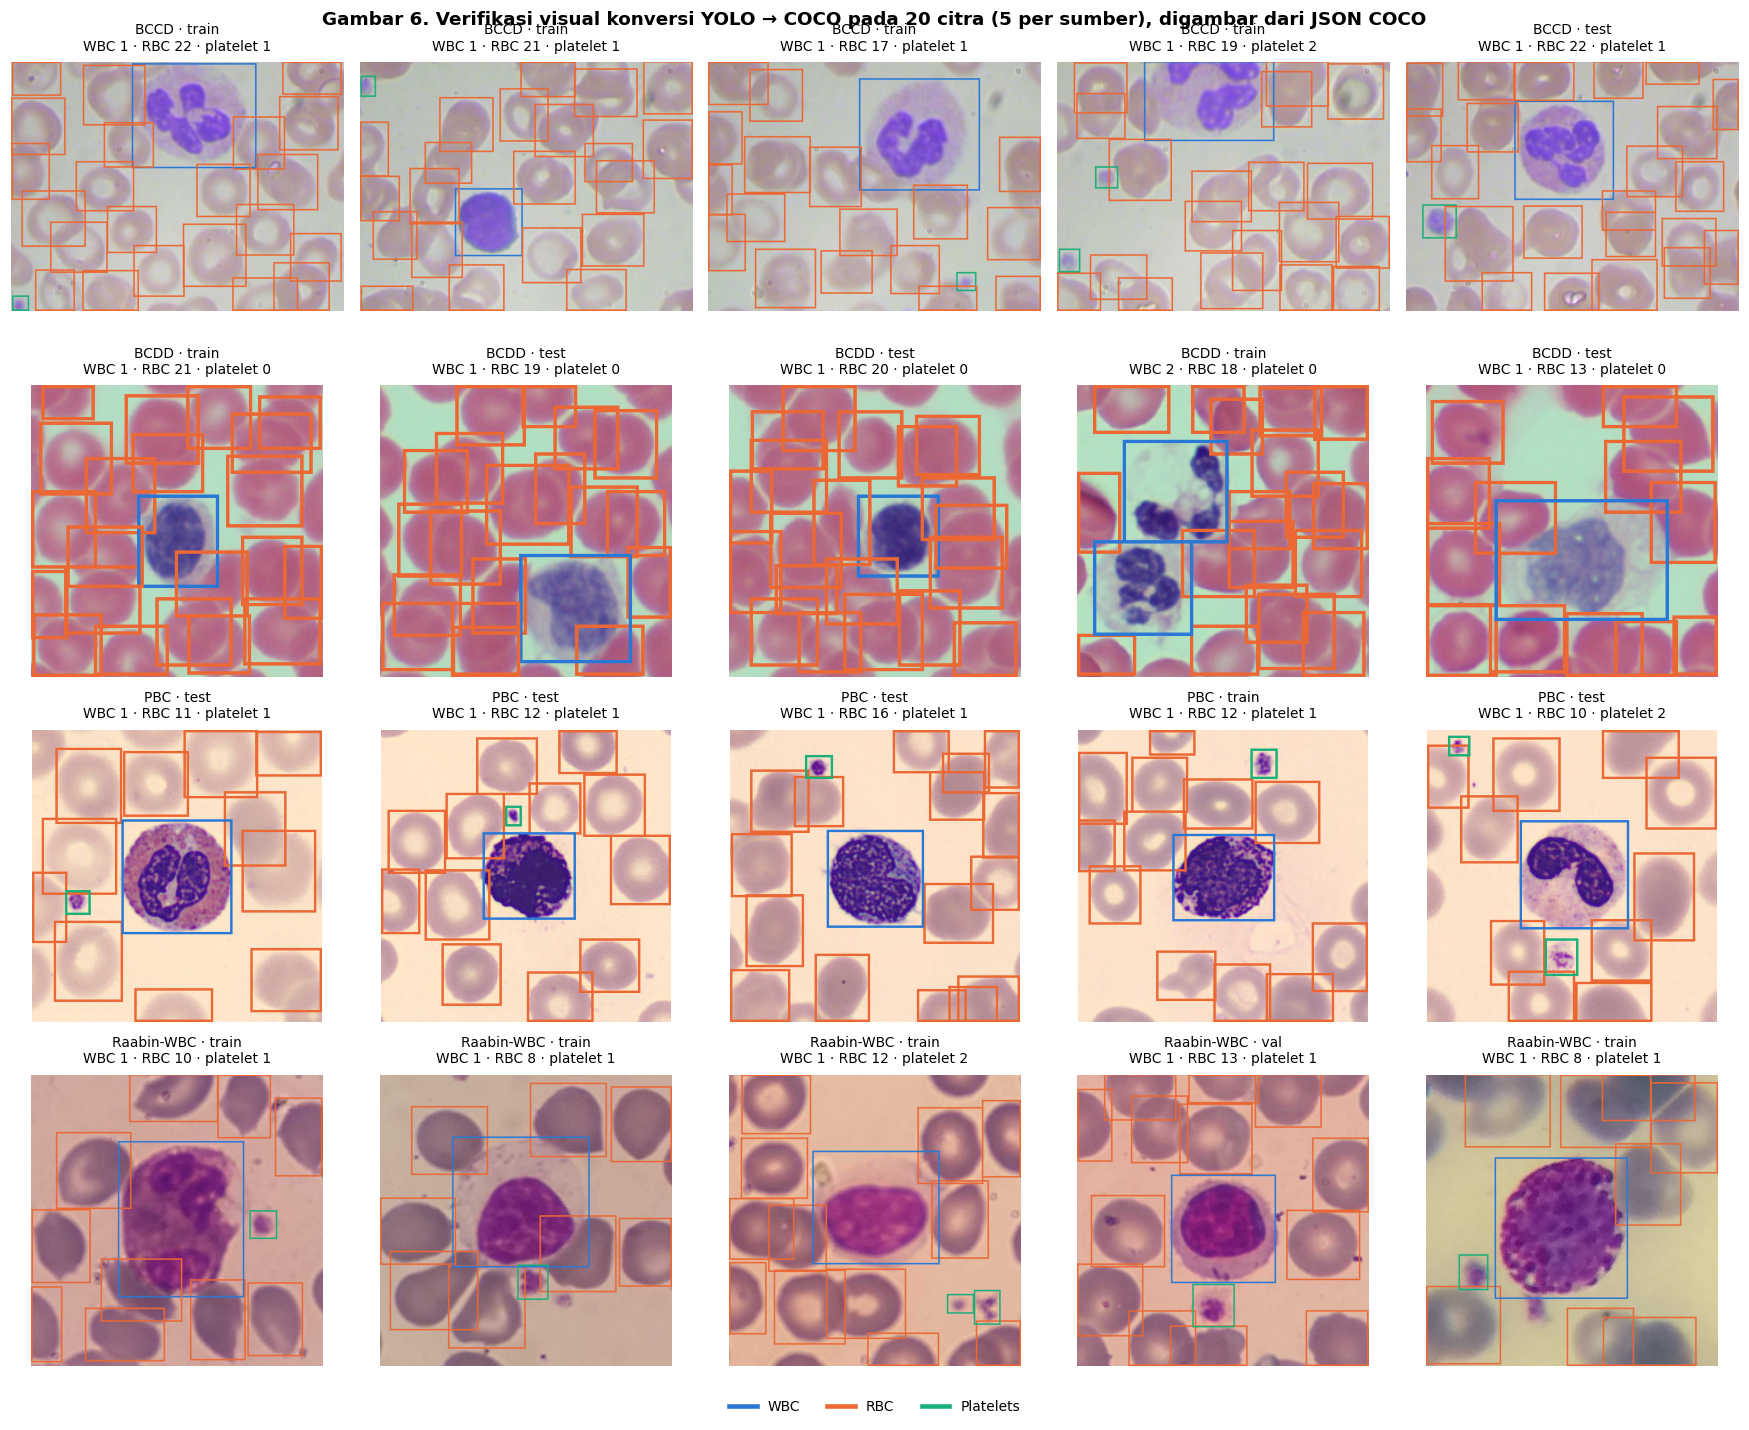

In [ ]:
# Verifikasi visual: 20 citra (5 per sumber, seed 42) digambar dari COCO JSON, bukan dari label YOLO
src_map = load_source_map(DATA_ROOT)
COLORS = {i + 1: CLASS_COLORS[c] for i, c in enumerate(CLASSES)}
pool = [(s, im) for s in SPLITS for im in coco[s]["images"]]
df_pool = pd.DataFrame([dict(split=s, id=im["id"], file=im["file_name"], source=src_map[im["file_name"][:-4]]) for s, im in pool])
# ambil citra yang mengandung platelet bila ada, agar kotak kecil ikut terverifikasi
has_plt = {(s, a["image_id"]) for s in SPLITS for a in coco[s]["annotations"] if a["category_id"] == 3}
df_pool["platelet"] = [(r.split, r.id) in has_plt for r in df_pool.itertuples()]
df_pool = df_pool.sort_values(["platelet", "split", "id"], ascending=[False, True, True])
picks = pd.concat([g.head(40).sample(5, random_state=SEED) for _, g in df_pool.groupby("source")])

fig, axes = plt.subplots(4, 5, figsize=(16, 13))
verif = []
for ax, r in zip(axes.flat, picks.itertuples()):
    im = Image.open(DATA_ROOT / "images" / r.split / r.file).convert("RGB")
    d = ImageDraw.Draw(im)
    anns = [a for a in coco[r.split]["annotations"] if a["image_id"] == r.id]
    for a in anns:
        x, y, w, h = a["bbox"]
        d.rectangle([x, y, x + w, y + h], outline=COLORS[a["category_id"]], width=3)
    n = pd.Series([a["category_id"] for a in anns]).value_counts()
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"{r.source} · {r.split}\nWBC {n.get(1,0)} · RBC {n.get(2,0)} · platelet {n.get(3,0)}", fontsize=9, fontweight="normal")
    verif.append(dict(split=r.split, file=r.file, source=r.source, kotak=len(anns)))
handles = [plt.Line2D([], [], color=c, lw=3, label=k) for k, c in CLASS_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Gambar 6. Verifikasi visual konversi YOLO → COCO pada 20 citra (5 per sumber), digambar dari JSON COCO", fontweight="semibold")
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG_DIR / "fig6_verifikasi_konversi_20_citra.png")
plt.show()
pd.DataFrame(verif).to_csv(OUTPUT_DIR / "coco_verifikasi_20_citra.csv", index=False)

### B.4 Pemeriksaan duplikat dan kebocoran
- **MD5**: berkas identik byte per byte.
- **pHash** (64 bit, algoritma sama dengan `imagehash.phash`, ditulis ulang di `src/leakage.py`): citra yang tampak mirip
  walau berbeda ukuran/kompresi. Pasangan dengan jarak Hamming ≤ 8 dianggap mirip.

Diperiksa antar-split (latih–validasi, latih–uji, validasi–uji) dan di dalam tiap split.

In [ ]:
H = {s: hash_split(DATA_ROOT, s, read_split_file(s)) for s in SPLITS}
all_h = pd.concat(H.values(), ignore_index=True)
md5_dup = all_h[all_h.duplicated("md5", keep=False)]
print("Berkas identik (MD5) di seluruh dataset:", len(md5_dup))

res, pairs_all = [], []
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    p = cross_pairs(H[a], H[b], max_dist=8)
    pairs_all.append(p)
    res.append(dict(pasangan=f"{a}–{b}", **{f"Hamming≤{t}": int((p.hamming <= t).sum()) for t in (0, 4, 8)}))
for s in SPLITS:
    p = cross_pairs(H[s], H[s], max_dist=8, same=True)
    pairs_all.append(p)
    res.append(dict(pasangan=f"{s}–{s} (di dalam)", **{f"Hamming≤{t}": int((p.hamming <= t).sum()) for t in (0, 4, 8)}))
pairs_all = pd.concat(pairs_all, ignore_index=True)
pairs_all.to_csv(LEAK_DIR / "phash_pairs_le8.csv", index=False)
tab_leak = pd.DataFrame(res).set_index("pasangan")
tab_leak.to_csv(LEAK_DIR / "ringkasan_kebocoran.csv")
tab_leak

Berkas identik (MD5) di seluruh dataset: 0


,Hamming≤0,Hamming≤4,Hamming≤8
pasangan,,,
train–val,0,1,2
train–test,0,0,0
val–test,0,0,0
train–train (di dalam),0,2,7
val–val (di dalam),0,0,0
test–test (di dalam),0,0,0


pasangan
split_a split_b sumber_a            
train   train   BCDD               2
                Raabin-WBC         5
        val     Raabin-WBC         2

Sebaran jarak Hamming minimum citra validasi/uji ke citra latih terdekat:


,min,25%,50%,mean
split,,,,
test,10.0,16.0,16.0,16.17
val,4.0,14.0,16.0,16.17


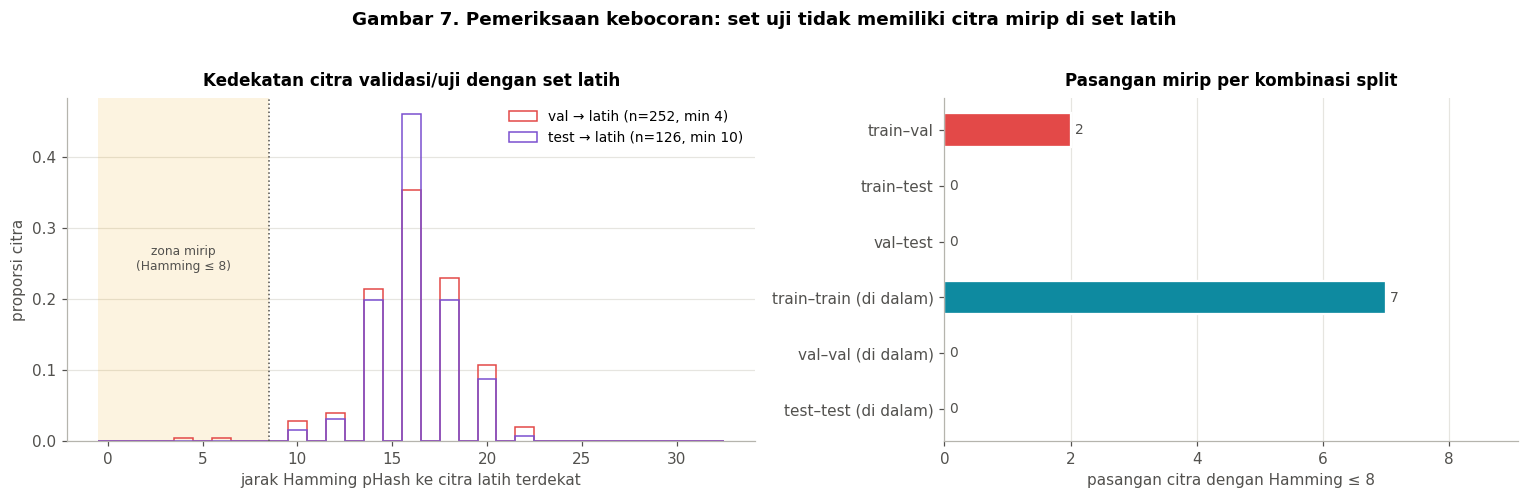

In [ ]:
# Sumber dataset dari setiap pasangan mirip, dan jarak terdekat tiap citra uji/validasi ke set latih
pairs_all["sumber_a"] = pairs_all.stem_a.map(src_map)
pairs_all["sumber_b"] = pairs_all.stem_b.map(src_map)
if len(pairs_all):
    display(pairs_all.groupby(["split_a", "split_b", "sumber_a"]).size().rename("pasangan").to_frame())

A = np.stack(H["train"].phash.values)
near = []
for s in ["val", "test"]:
    B = np.stack(H[s].phash.values)
    dmin = (B[:, None, :] != A[None, :, :]).sum(-1).min(1)
    near.append(pd.DataFrame({"split": s, "stem": H[s].stem, "jarak_min_ke_latih": dmin}))
near = pd.concat(near)
near.to_csv(LEAK_DIR / "jarak_min_ke_latih.csv", index=False)
print("Sebaran jarak Hamming minimum citra validasi/uji ke citra latih terdekat:")
display(near.groupby("split").jarak_min_ke_latih.describe()[["min", "25%", "50%", "mean"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax = axes[0]
for sp, ls in [("val", "-"), ("test", "--")]:
    d = near[near.split == sp].jarak_min_ke_latih
    ax.hist(d, bins=np.arange(-0.5, 33, 1), histtype="step", lw=2.2, ls=ls, color=SPLIT_COLORS[sp], density=True,
            label=f"{sp} → latih (n={len(d)}, min {d.min()})")
ax.axvspan(-0.5, 8.5, color="#eda100", alpha=0.12, lw=0)
ax.axvline(8.5, color=INK_2, ls=":", lw=1); ax.text(4, ax.get_ylim()[1] * 0.5, "zona mirip\n(Hamming ≤ 8)", fontsize=8, color=INK_2, ha="center")
ax.set_xlabel("jarak Hamming pHash ke citra latih terdekat"); ax.set_ylabel("proporsi citra")
ax.set_title("Kedekatan citra validasi/uji dengan set latih"); ax.legend(loc="upper right")

ax = axes[1]
lab = list(tab_leak.index)
vals = tab_leak["Hamming≤8"].values
cols = [SPLIT_COLORS[l.split(" ")[0].split("–")[1]] for l in lab]   # warna = split kedua pada pasangan
bars = ax.barh(lab[::-1], vals[::-1], color=cols[::-1], height=0.6, **BAR)
for b_ in bars:
    ax.annotate(f"{int(b_.get_width())}", (b_.get_width(), b_.get_y() + b_.get_height() / 2), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(vals.max(), 1) * 1.3); ax.set_xlabel("pasangan citra dengan Hamming ≤ 8")
ax.set_title("Pasangan mirip per kombinasi split")
fig.suptitle("Gambar 7. Pemeriksaan kebocoran: set uji tidak memiliki citra mirip di set latih", fontweight="semibold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_pemeriksaan_kebocoran.png")
plt.show()

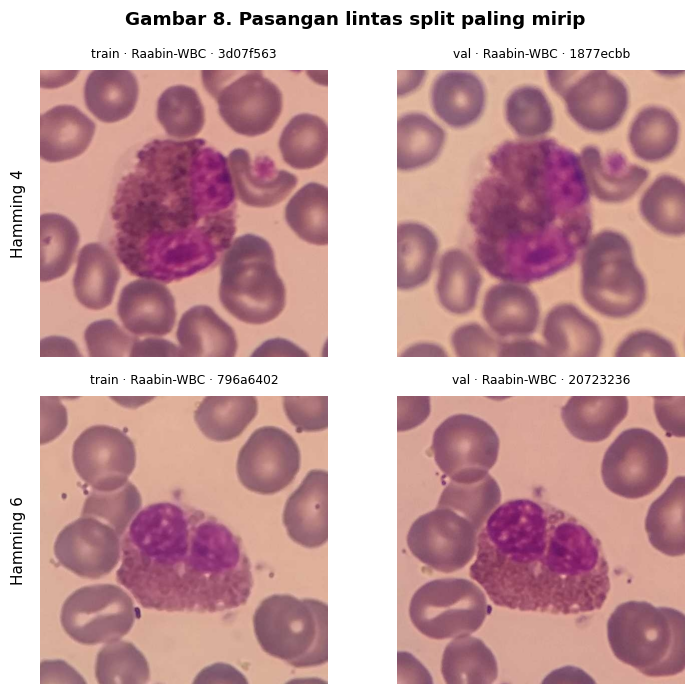

In [ ]:
# Tampilkan pasangan lintas split paling mirip (maks 6) untuk diperiksa mata
cross = pairs_all[pairs_all.split_a != pairs_all.split_b].head(6)
if len(cross) == 0:
    print("Tidak ada pasangan lintas split dengan Hamming <= 8.")
    # tetap tampilkan 3 pasangan latih-uji terdekat sebagai bukti pemeriksaan
    B = np.stack(H["test"].phash.values)
    D = (B[:, None, :] != A[None, :, :]).sum(-1)
    idx = np.dstack(np.unravel_index(np.argsort(D, axis=None)[:3], D.shape))[0]
    cross = pd.DataFrame([dict(split_a="test", stem_a=H["test"].stem.iloc[i], split_b="train",
                               stem_b=H["train"].stem.iloc[j], hamming=int(D[i, j])) for i, j in idx])
fig, axes = plt.subplots(len(cross), 2, figsize=(7, 3.2 * len(cross)))
axes = np.atleast_2d(axes)
for k, r in enumerate(cross.itertuples()):
    for j, (sp, st) in enumerate([(r.split_a, r.stem_a), (r.split_b, r.stem_b)]):
        axes[k, j].imshow(Image.open(DATA_ROOT / "images" / sp / f"{st}.png")); axes[k, j].axis("off")
        axes[k, j].set_title(f"{sp} · {src_map[st]} · {st[:8]}", fontsize=8, fontweight="normal")
    axes[k, 0].text(-0.05, 0.5, f"Hamming {r.hamming}", transform=axes[k, 0].transAxes, rotation=90, va="center", ha="right")
fig.suptitle("Gambar 8. Pasangan lintas split paling mirip", fontweight="semibold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig8_pasangan_terdekat.png")
plt.show()

### B.5 Ringkasan dan keputusan

| Pemeriksaan | Hasil | Keputusan |
|---|---|---|
| Split resmi | 882 / 252 / 126 citra, tidak ada nama berkas yang sama antar-split, semua citra punya label | Dipakai apa adanya; daftar berkas tersimpan di `splits/`. |
| Keabsahan label | 0 kelas di luar 0–2, 0 koordinat tidak sah; 47 baris duplikat di 5 berkas | Duplikat dibuang saat konversi (18.096 kotak unik). |
| Konversi COCO | Jumlah kotak COCO = jumlah kotak YOLO unik di tiap split; selisih bolak-balik maks 0,007 px | Konversi benar secara numerik. |
| Verifikasi visual | 20 citra (5 per sumber, sebagian besar memuat platelet): semua kotak tepat menempel pada sel | Konversi benar secara visual. Catatan: beberapa partikel kecil di citra Raabin tampak tidak berlabel; diperiksa lagi saat analisis false positive platelet di M3. |
| Identik (MD5) | 0 berkas identik di seluruh dataset | — |
| pHash latih–uji | **0 pasangan** dengan Hamming ≤ 8; jarak terdekat citra uji ke latih = 10 (median 16) | **Set uji bersih** dari duplikat/kemiripan tinggi terhadap set latih. |
| pHash latih–validasi | 2 pasangan (Hamming 4 dan 6), keduanya Raabin-WBC: sel WBC yang sama dengan bidang pandang sedikit bergeser | Split resmi tidak diubah. 2 dari 252 citra validasi (0,8%) ditandai; dampaknya hanya pada pemilihan model, bukan angka uji. Disebutkan di laporan. |
| pHash di dalam split | 7 pasangan di set latih (5 Raabin-WBC, 2 BCDD), 0 di validasi dan uji | Bukan kebocoran (sesama data latih); hanya menambah sedikit redundansi. |

## Bagian C · Baseline R01 YOLOv8s (one-stage) — Tsabita
Konfigurasi lengkap di `configs/R01.yaml`: pralatih COCO, fine-tune penuh, 60 epoch (berhenti dini bila val tidak membaik 15 epoch), imgsz 640, batch 16, SGD lr 0,01,
augmentasi flip H/V + skala ±20% + hue ±0,01 (mosaic dimatikan agar sama dengan Faster R-CNN), seed 42.
Setelah pelatihan, prediksi set **validasi** diekspor ke format COCO dan dinilai dengan pycocotools.
Set uji tidak dipakai.

> Butuh GPU: **Runtime → Change runtime type → T4 GPU**. Pelatihan berjalan di **proses Python terpisah**
> (`src/run_job.py`), sehingga setelah selesai seluruh VRAM dan RAM dilepas. Baseline yang sudah selesai di-SKIP.
> Dua akun bisa jalan bersamaan: isi `PELAKSANA` di sel berikut (`"Tsabita"` → R01, `"Putri"` → R02). Lihat `SKENARIO.md`.

In [ ]:
# ---- Baseline yang dijalankan di sesi ini (tiap anggota memakai akun Colab sendiri) ----
PELAKSANA = "semua"    # "semua", "Tsabita" (hanya R01), atau "Putri" (hanya R02) — lihat SKENARIO.md
JALANKAN_R01 = PELAKSANA in ("semua", "Tsabita")   # Tsabita · YOLOv8s
JALANKAN_R02 = PELAKSANA in ("semua", "Putri")     # Putri   · Faster R-CNN
# Baseline yang sudah selesai otomatis dilewati (SKIP), jadi aman bila notebook dijalankan ulang.

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # kurangi fragmentasi VRAM
import time
import pandas as pd
import matplotlib.pyplot as plt
from src import pipeline as P
from src.exp_log import read_log, gpu_name

RUNS_DIR = PROJECT_ROOT / "runs"      # bobot & checkpoint di Google Drive (aman bila sesi putus)
P.ensure_coco(DATA_ROOT)

def status(run_id):
    log = read_log().set_index("run_id")
    return log.loc[run_id, "status"] if run_id in log.index else "planned"

perlu_gpu = [r for r, on in [("R01", JALANKAN_R01), ("R02", JALANKAN_R02)] if on and status(r) != "done"]
if perlu_gpu:
    import torch
    assert torch.cuda.is_available(), "GPU belum aktif: Runtime > Change runtime type > T4 GPU"
    free, total = torch.cuda.mem_get_info()
    print(f"GPU {gpu_name()} · VRAM {total / 1024**3:.1f} GB total, {free / 1024**3:.1f} GB bebas · torch {torch.__version__}")
print("Baseline yang akan dilatih di sesi ini:", perlu_gpu or "tidak ada (semua sudah selesai)")

def jalankan_baseline(run_id):
    """Seperti M3: lewati bila selesai; selain itu latih di proses terpisah agar VRAM/RAM kosong kembali."""
    if status(run_id) == "done" and (PRED_DIR / f"{run_id}_val.json").exists():
        print(f"SKIP (sudah selesai): {run_id}")
        row = read_log().set_index("run_id").loc[run_id]
        return {k.replace("val_", ""): row[k] for k in ["val_mAP50", "val_mAP50_95", "val_AP_small", "val_MAE_WBC", "val_MAE_RBC", "val_MAE_Platelets"]}
    t0 = time.perf_counter()
    print(f"MULAI {run_id} · VRAM terpakai sebelum: {P.gpu_used_gb():.2f} GB")
    m = P.run_isolated(run_id, DATA_ROOT)
    print(f"{run_id} selesai ({(time.perf_counter() - t0) / 60:.1f} mnt) · VRAM terpakai sesudah: {P.gpu_used_gb():.2f} GB")
    return m

GPU Tesla T4 · VRAM 14.6 GB total, 14.5 GB bebas · torch 2.14.1+cu130
Baseline yang akan dilatih di sesi ini: ['R01', 'R02']


In [ ]:
if JALANKAN_R01:
    m_r01 = jalankan_baseline("R01")
    display(pd.Series(m_r01).astype(float).round(4).to_frame("R01 (validasi)").T)
else:
    print("R01 tidak dijalankan di sesi ini.")

MULAI R01 · VRAM terpakai sebelum: 0.10 GB
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_txl.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, 

,mAP50_95,mAP50,mAP75,AP_small,AP_medium,AP_large,AR100,AP50_95_WBC,AP50_WBC,APsmall_WBC,AP50_95_RBC,AP50_RBC,APsmall_RBC,AP50_95_Platelets,AP50_Platelets,APsmall_Platelets,MAE_WBC,MAPE_WBC,MAE_RBC,MAPE_RBC,MAE_Platelets,MAPE_Platelets
R01 (validasi),0.85,0.97,0.94,0.73,0.86,0.89,0.88,0.89,0.99,NaN,0.89,0.98,NaN,0.77,0.95,0.73,7.90e-03,0.2,0.96,7.51,0.08,16.17


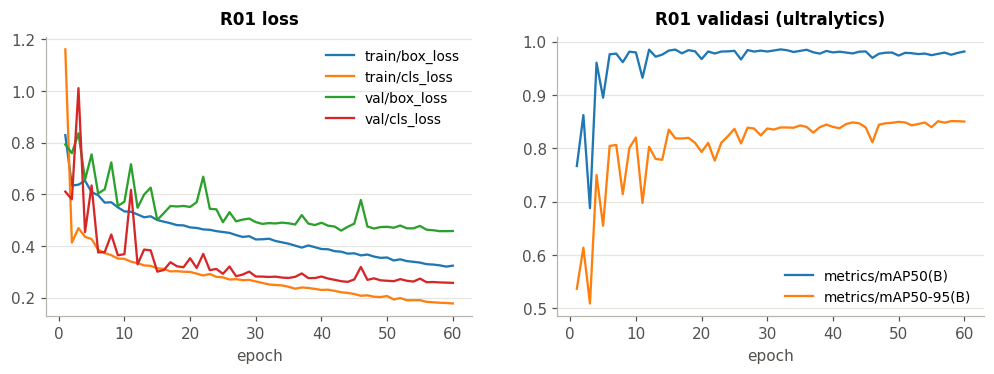

In [ ]:
# kurva pelatihan R01 (hanya untuk memantau; angka laporan berasal dari pycocotools)
f = RUNS_DIR / "R01" / "results.csv"
if f.exists():
    res = pd.read_csv(f); res.columns = [c.strip() for c in res.columns]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
    for c in ["train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss"]:
        ax[0].plot(res["epoch"], res[c], label=c)
    ax[0].set_title("R01 loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    for c in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
        ax[1].plot(res["epoch"], res[c], label=c)
    ax[1].set_title("R01 validasi (ultralytics)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    fig.savefig(RUNS_DIR / "R01" / "kurva.png", dpi=120, bbox_inches="tight")
else:
    print("R01 belum dilatih.")

## Bagian D · Baseline R02 Faster R-CNN ResNet-50-FPN (two-stage) — Putri
Konfigurasi lengkap di `configs/R02.yaml`: pralatih COCO, fine-tune penuh, 12 epoch (jadwal standar 1×), batch 4, SGD lr 0,01 (turun ×0,1
di epoch 8 dan 11; val dievaluasi mulai epoch 6), sisi pendek acak 512–768 saat latih dan 640 saat inferensi, anchor 32–512, AMP, seed 42.
Model terbaik dipilih dengan fitness 0,1·mAP50 + 0,9·mAP50-95 di validasi (rumus sama dengan ultralytics).
Checkpoint disimpan tiap epoch; bila sesi putus, jalankan ulang sel ini dan pelatihan dilanjutkan.

In [ ]:
if JALANKAN_R02:
    m_r02 = jalankan_baseline("R02")
    display(pd.Series(m_r02).astype(float).round(4).to_frame("R02 (validasi)").T)
else:
    print("R02 tidak dijalankan di sesi ini.")

MULAI R02 · VRAM terpakai sebelum: 0.10 GB
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
  epoch 1 iter 50/220 loss 1.4850 lr 0.00164
  epoch 1 iter 100/220 loss 1.0043 lr 0.00331
  epoch 1 iter 150/220 loss 0.8103 lr 0.00497
  epoch 1 iter 200/220 loss 0.6994 lr 0.00664
epoch 1/12  loss 0.6695  val mAP50 nan  mAP50-95 nan  GPU puncak 5.5 GB  (1.9 mnt)
  epoch 2 iter 50/220 loss 0.3516 lr 0.00897
  epoch 2 iter 100/220 loss 0.3562 lr 0.01000
  epoch 2 iter 150/220 loss 0.3419 lr 0.01000
  epoch 2 iter 200/220 loss 0.3316 lr 0.01000
epoch 2/12  loss 0.3286  val mAP50 nan  mAP50-95 nan  GPU puncak 5.6 GB  (1.9 mnt)
  epoch 3 iter 50/220 loss 0.2903 lr 0.01000
  epoch 3 iter 100/220 loss 0.2818 lr 0.01000
  epoch 3 iter 150/220 loss 0.2814 lr 0.01000
  epoch 3 iter 200/220 loss 0.2850 lr 0.01000
epoch 3/12  loss 0.2844  val mAP50 nan  mAP50-95 nan  GPU puncak 5.5 

,mAP50_95,mAP50,mAP75,AP_small,AP_medium,AP_large,AR100,AP50_95_WBC,AP50_WBC,APsmall_WBC,AP50_95_RBC,AP50_RBC,APsmall_RBC,AP50_95_Platelets,AP50_Platelets,APsmall_Platelets,MAE_WBC,MAPE_WBC,MAE_RBC,MAPE_RBC,MAE_Platelets,MAPE_Platelets
R02 (validasi),0.82,0.98,0.94,0.73,0.83,0.86,0.87,0.86,0.99,NaN,0.87,0.98,NaN,0.75,0.97,0.73,0.01,0.6,0.68,5.22,0.05,7.73


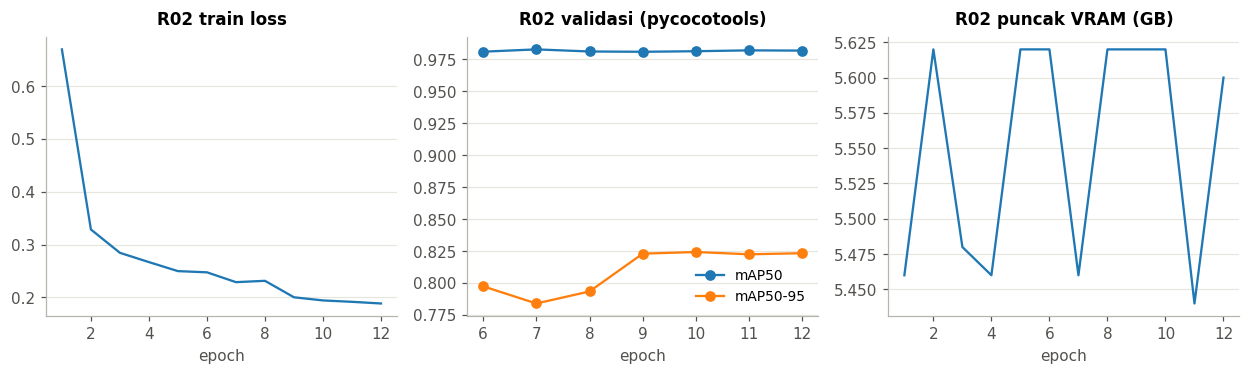

In [ ]:
f = RUNS_DIR / "R02" / "history.csv"
if f.exists():
    hist = pd.read_csv(f)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
    ax[0].plot(hist.epoch, hist.train_loss); ax[0].set_title("R02 train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(hist.epoch, hist.val_mAP50, "o-", label="mAP50"); ax[1].plot(hist.epoch, hist.val_mAP50_95, "o-", label="mAP50-95")  # epoch awal tidak dievaluasi (hemat)
    ax[1].set_title("R02 validasi (pycocotools)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    ax[2].plot(hist.epoch, hist.gpu_peak_gb); ax[2].set_title("R02 puncak VRAM (GB)"); ax[2].set_xlabel("epoch")
    fig.savefig(RUNS_DIR / "R02" / "kurva.png", dpi=120, bbox_inches="tight")
else:
    print("R02 belum dilatih.")

## Bagian E · Evaluasi Terpadu Baseline — Tsabita
Kedua baseline dinilai dengan **alat yang sama** (pycocotools) dari berkas prediksi `outputs/preds/R01_val.json` dan
`R02_val.json`, lalu galat hitung sel per citra (MAE, MAPE) dengan τ per kelas yang dipilih di validasi.
Bagian ini tidak butuh GPU; dijalankan Tsabita setelah Bagian C dan D selesai.

In [ ]:
RUNS = ["R01", "R02"]
belum = [r for r in RUNS if not (PRED_DIR / f"{r}_val.json").exists()]
E_OK = not belum
if not E_OK:   # dua akun berjalan bersamaan: yang selesai duluan cukup melewati Bagian E (tanpa error)
    print(f"TUNDA: Bagian E menunggu {belum} selesai (akun lain). Jalankan ulang notebook ini setelahnya; R01/R02 akan di-SKIP.")
if E_OK:
    import json
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from src.evaluate import coco_metrics, gt_counts, pred_counts, count_errors, select_tau, load_json
    from src.data_utils import load_source_map
    from src.viz import style, MODEL_COLORS
    style()

    EVAL_DIR = OUTPUT_DIR / "eval"
    EVAL_DIR.mkdir(parents=True, exist_ok=True)
    GT_VAL = COCO_DIR / "val.json"
    dets = {r: load_json(PRED_DIR / f"{r}_val.json") for r in RUNS}
    print({r: len(d) for r, d in dets.items()}, "deteksi")

{'R01': 5813, 'R02': 12931} deteksi


### E.1 Metrik deteksi (pycocotools) di set validasi

In [ ]:
if E_OK:
    rows = {}
    for r in RUNS:
        print(f"===== {r} =====")
        rows[r] = coco_metrics(GT_VAL, dets[r])
    det_tab = pd.DataFrame(rows).T
    cols = ["mAP50", "mAP50_95", "AP_small"] + [f"AP50_95_{c}" for c in CLASSES] + [f"AP50_{c}" for c in CLASSES] + ["APsmall_Platelets"]
    det_tab = det_tab[cols]
    det_tab.to_csv(EVAL_DIR / "val_deteksi.csv")
    display(det_tab.round(4))

===== R01 =====
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.58s).
Accumulating evaluation results...
DONE (t=0.11s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.848
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.972
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.939
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.727
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.855
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.887
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.480
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.798
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=

,mAP50,mAP50_95,AP_small,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelets,AP50_WBC,AP50_RBC,AP50_Platelets,APsmall_Platelets
R01,0.97,0.85,0.73,0.89,0.89,0.77,0.99,0.98,0.95,0.73
R02,0.98,0.82,0.73,0.86,0.87,0.75,0.99,0.98,0.97,0.73


### E.2 Galat hitung sel per citra
τ dipilih per kelas untuk tiap run dengan meminimalkan MAE di validasi (kisi 0,05–0,95).

In [ ]:
if E_OK:
    gt = gt_counts(GT_VAL)
    taus, curves, err_rows, pc = {}, {}, [], {}
    for r in RUNS:
        taus[r], curves[r] = select_tau(GT_VAL, dets[r])
        pc[r] = pred_counts(dets[r], list(gt.index), taus[r])
        e = count_errors(gt, pc[r])
        for c in CLASSES:
            err_rows.append(dict(run=r, kelas=c, tau=taus[r][c], **e.loc[c].to_dict()))
    cnt_tab = pd.DataFrame(err_rows).set_index(["run", "kelas"])
    cnt_tab.to_csv(EVAL_DIR / "val_galat_hitung.csv")
    display(cnt_tab.round(3))

tau       MAE   MAPE      bias  n_img  n_mape
run kelas                                                    
R01 WBC        0.70  8.00e-03   0.20  0.00e+00  252.0   250.0
    RBC        0.70  9.60e-01   7.51  7.10e-02  252.0   252.0
    Platelets  0.75  7.50e-02  16.17 -3.60e-02  252.0    64.0
R02 WBC        0.30  1.20e-02   0.60  4.00e-03  252.0   250.0
    RBC        0.70  6.79e-01   5.22  9.90e-02  252.0   252.0
    Platelets  0.90  4.80e-02   7.73 -2.40e-02  252.0    64.0

None

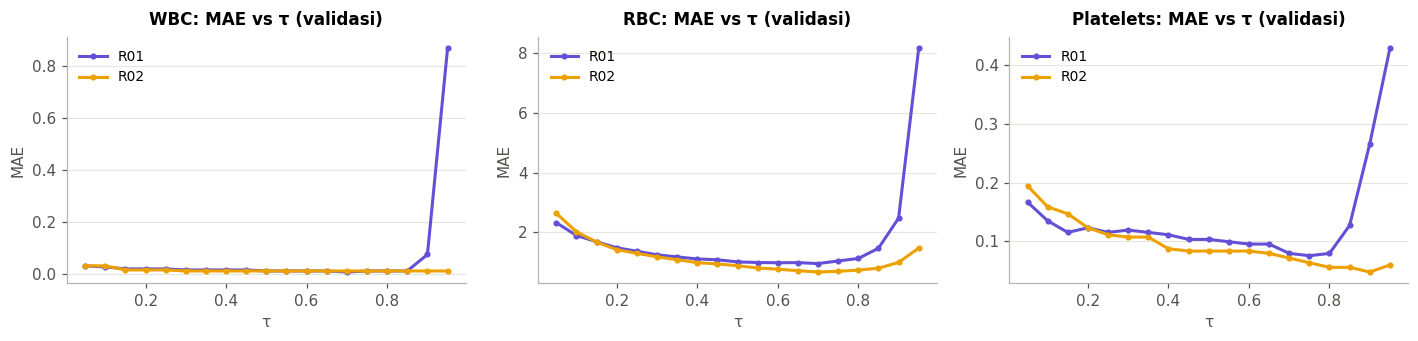

In [ ]:
if E_OK:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    for ax, c in zip(axes, CLASSES):
        for r in RUNS:
            cv = curves[r][curves[r].kelas == c]
            ax.plot(cv.tau, cv.MAE, marker=".", lw=2, label=r,
                    color={"R01": MODEL_COLORS["YOLOv8s"], "R02": MODEL_COLORS["Faster R-CNN"]}.get(r))
        ax.set_title(f"{c}: MAE vs τ (validasi)"); ax.set_xlabel("τ"); ax.set_ylabel("MAE"); ax.legend()
    fig.tight_layout()
    display(fig.savefig(EVAL_DIR / "val_mae_vs_tau.png", dpi=130, bbox_inches="tight"))

### E.3 Apakah peringkat mAP sama dengan peringkat galat hitung? (RQ1, data validasi)

In [ ]:
if E_OK:
    rank = pd.DataFrame({
        "mAP50_95": det_tab["mAP50_95"],
        **{f"AP50_95_{c}": det_tab[f"AP50_95_{c}"] for c in CLASSES},
        **{f"MAE_{c}": cnt_tab.xs(c, level="kelas")["MAE"] for c in CLASSES},
    })
    print("Peringkat (1 = terbaik; AP makin tinggi makin baik, MAE makin rendah makin baik):")
    rk = pd.concat([rank.filter(like="AP").rank(ascending=False, method="min"), rank.filter(like="MAE").rank(ascending=True, method="min")], axis=1).astype(int)
    display(rk)

Peringkat (1 = terbaik; AP makin tinggi makin baik, MAE makin rendah makin baik):


,mAP50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelets,MAE_WBC,MAE_RBC,MAE_Platelets
R01,1,1,1,1,1,2,2
R02,2,2,2,2,2,1,1


### E.4 Galat hitung per sumber dan per kepadatan RBC (bahan RQ2/H2)

In [ ]:
if E_OK:
    val_imgs = load_json(GT_VAL)["images"]
    src_map = load_source_map(DATA_ROOT)
    meta = pd.DataFrame({"image_id": [i["id"] for i in val_imgs],
                         "source": [src_map[i["file_name"][:-4]] for i in val_imgs]}).set_index("image_id")
    meta["padat"] = np.where(gt["RBC"] > 15, "RBC>15", "RBC<=15")

    per = []
    for r in RUNS:
        err = (pc[r] - gt).abs()
        for grp in ["source", "padat"]:
            t = err.join(meta).groupby(grp)[CLASSES].mean()
            t["n_citra"] = meta.groupby(grp).size()
            t["run"], t["kelompok"] = r, grp
            per.append(t.reset_index().rename(columns={grp: "nilai"}))
    per = pd.concat(per).set_index(["kelompok", "nilai", "run"]).sort_index()
    per.to_csv(EVAL_DIR / "val_mae_per_kelompok.csv")
    display(per.round(3))

WBC   RBC  Platelets  n_citra
kelompok nilai      run                                
padat    RBC<=15    R01  0.01  0.78       0.07      183
                    R02  0.02  0.56       0.04      183
         RBC>15     R01  0.00  1.44       0.09       69
                    R02  0.00  0.99       0.06       69
source   BCCD       R01  0.00  1.78       0.15       41
                    R02  0.00  1.24       0.10       41
         BCDD       R01  0.00  0.88       0.00       16
                    R02  0.00  0.69       0.00       16
         PBC        R01  0.00  0.81       0.10       97
                    R02  0.01  0.55       0.05       97
         Raabin-WBC R01  0.02  0.78       0.03       98
                    R02  0.02  0.57       0.03       98

In [ ]:
if E_OK:
    # bias: positif = model menghitung lebih banyak, negatif = kurang
    bias = pd.concat({r: (pc[r] - gt).join(meta).groupby("padat")[CLASSES].mean() for r in RUNS})
    display(bias.round(3))

WBC   RBC  Platelets
    padat                             
R01 RBC<=15  0.00e+00  0.43      -0.03
    RBC>15   0.00e+00 -0.88      -0.06
R02 RBC<=15  5.00e-03  0.15      -0.02
    RBC>15   0.00e+00 -0.03      -0.03

### E.5 Set uji (DIKUNCI sampai M3)
Ubah `FINAL_TEST = True` **satu kali** di M3 setelah dua konfigurasi final ditetapkan dari hasil validasi.
τ yang dipakai adalah τ hasil validasi di atas; tidak ada penyesuaian apa pun di set uji.

In [ ]:
if E_OK:
    FINAL_TEST = False
    FINAL_RUNS = []   # diisi di M3, mis. ["R0x", "R0y"]; prediksi uji dibuat di notebook 03/04 dengan bobot final
    if FINAL_TEST:
        from src.evaluate import evaluate_run
        out = {}
        for r in FINAL_RUNS:
            d = load_json(PRED_DIR / f"{r}_test.json")
            tau_val, _ = select_tau(GT_VAL, load_json(PRED_DIR / f"{r}_val.json"))
            out[r] = evaluate_run(COCO_DIR / "test.json", d, tau_val)
        pd.DataFrame(out).T.to_csv(EVAL_DIR / "test_final.csv")
        display(pd.DataFrame(out).T.round(4))
    else:
        print("Set uji belum dibuka (sesuai kisi-kisi: hanya sekali untuk konfigurasi final).")

Set uji belum dibuka (sesuai kisi-kisi: hanya sekali untuk konfigurasi final).


## Bagian F · Penutup M2: log eksperimen dan berkas hasil — Bersama
Semua run (termasuk yang gagal) tercatat di `experiments/log.csv`. Karena folder proyek berada di Google Drive,
seluruh hasil (split, tabel EDA, kebocoran, bobot `runs/`, prediksi, evaluasi) sudah tersimpan otomatis.

In [ ]:
from src.exp_log import read_log
log = read_log()
display((log[log.status != "planned"] if (log.status != "planned").any() else log).drop(columns=["date"], errors="ignore").fillna("–"))

print("Berkas hasil M2:")
for d in ["splits", "outputs/eda", "outputs/leakage", "outputs/preds", "outputs/eval", "experiments"]:
    p = PROJECT_ROOT / d
    if p.exists():
        files = sorted(x.name for x in p.iterdir() if x.is_file())
        print(f"  {d}/ ({len(files)} berkas): {', '.join(files[:8])}{' ...' if len(files) > 8 else ''}")

,run_id,owner,model,factor,value,seed,status,gpu,gpu_minutes,val_mAP50,val_mAP50_95,val_AP_small,val_MAE_WBC,val_MAE_RBC,val_MAE_Platelets,notes
0,R01,Tsabita,yolov8s,baseline,imgsz 640,42,done,Tesla T4,17.7,0.97,0.85,0.73,8.00e-03,0.96,0.07,"tau={'Platelets': 0.75, 'RBC': 0.7, 'WBC': 0.7..."
1,R02,Putri,fasterrcnn_resnet50_fpn,baseline,"anchor default, fine-tune penuh",42,done,Tesla T4,25.4,0.98,0.82,0.73,1.20e-02,0.68,0.05,"tau={'Platelets': 0.9, 'RBC': 0.7, 'WBC': 0.3}..."


Berkas hasil M2:
  splits/ (3 berkas): test.txt, train.txt, val.txt
  outputs/eda/ (9 berkas): citra_per_sumber_split.csv, distribusi_kelas.csv, kategori_ukuran.csv, kondisi_citra.csv, label_duplikat.csv, objek_per_citra.csv, rgb_per_sumber.csv, tumpang_tindih.csv ...
  outputs/leakage/ (3 berkas): jarak_min_ke_latih.csv, phash_pairs_le8.csv, ringkasan_kebocoran.csv
  outputs/preds/ (2 berkas): R01_val.json, R02_val.json
  outputs/eval/ (4 berkas): val_deteksi.csv, val_galat_hitung.csv, val_mae_per_kelompok.csv, val_mae_vs_tau.png
  experiments/ (1 berkas): log.csv
